# Lab 7 — Go-to-goal, student ID ending 45
The robot drives through points that draw the digits **4** and **5**. We compare the planned path, the simulator and the real robot.

Settings (same in both programs): `Kv = 1.5`, `Kθ = 4`, acceptance radius `ε = 2 cm`.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

try:                                   # in Colab: upload both txt files
    from google.colab import files
    files.upload()
except ImportError:                    # on a computer the files are already here
    pass

# planned points in cm (copied from the TRIK program)
wp = np.array([[0, 0], [0, -20], [20, -20], [20, 0], [20, -40],
               [40, -40], [60, -40], [60, -20], [40, -20], [40, 0], [60, 0]])

x_s, y_s, t_s = np.loadtxt('odometry_data_sim.txt',  delimiter=',', unpack=True)
x_r, y_r, t_r = np.loadtxt('odometry_data_real.txt', delimiter=',', unpack=True)

## 1. The paths

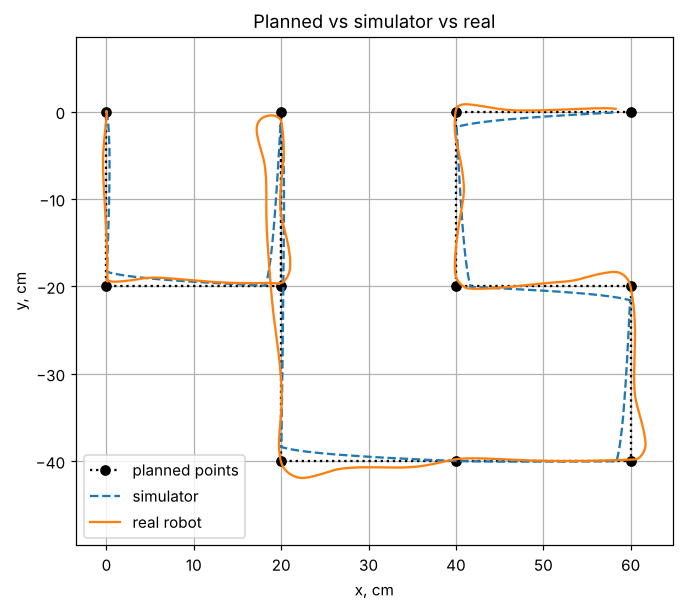

In [ ]:
plt.figure(figsize=(7, 6))
plt.plot(wp[:, 0], wp[:, 1], 'k:o', label='planned points')
plt.plot(x_s, y_s, '--', label='simulator')
plt.plot(x_r, y_r,       label='real robot')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x, cm'); plt.ylabel('y, cm')
plt.title('Planned vs simulator vs real')
plt.show()

## 2. How close did the robot get to each point? (cm)

In [ ]:
def miss(x, y):
    return [np.min(np.hypot(x - px, y - py)) for px, py in wp]

for i, (a, b) in enumerate(zip(miss(x_s, y_s), miss(x_r, y_r))):
    print(f'point {i:2d}: simulator {a:4.1f} | real {b:4.1f}')

point  0: simulator  0.0 | real  0.0
point  1: simulator  1.6 | real  0.6
point  2: simulator  0.3 | real  0.4
point  3: simulator  1.6 | real  0.8
point  4: simulator  1.6 | real  0.0
point  5: simulator  0.1 | real  0.3
point  6: simulator  1.6 | real  0.2
point  7: simulator  1.6 | real  0.1
point  8: simulator  1.6 | real  0.6
point  9: simulator  1.7 | real  0.1
point 10: simulator  1.6 | real  1.8


## 3. How long did it take?

In [ ]:
print(f'simulator: {(t_s[-1]-t_s[0])/1000:.0f} s')
print(f'real robot: {(t_r[-1]-t_r[0])/1000:.0f} s')

simulator: 27 s
real robot: 38 s


## 4. Where did the real robot really stop?
Measure with a tape (start = 0,0; x = forward) and type the numbers below.

In [ ]:
tape_x, tape_y = None, None      # <-- your measurement in cm, e.g. 57.0, 2.0

print(f'last waypoint     : (60, 0)')
print(f'robot thinks (odometry): ({x_r[-1]:.1f}, {y_r[-1]:.1f})')
if tape_x is not None:
    print(f'tape              : ({tape_x}, {tape_y})')
    print(f'error of odometry : {np.hypot(tape_x-x_r[-1], tape_y-y_r[-1]):.1f} cm')

last waypoint     : (60, 0)
robot thinks (odometry): (58.3, 0.3)


## Conclusion
The robot passed through every point to within about 2 cm, both in the simulator and on the real robot. The simulator cuts the corners a little, because the robot moves on to the next point as soon as it is within 2 cm (`ε`). The real robot goes slightly past some corners, for example (60, −40), because it cannot slow down below its minimum speed and its motors react with a delay. The real robot's path stays close to the simulator's, so the controller works the same way in both. Whether the rest of the difference is a *localization* problem depends on step 4: if the tape measurement is far from what the odometry says, the robot does not know where it really is; if it is close, the remaining error is only from control.